# CivicFlux — ML-Based Cascade Risk Analysis

## 01. Objective and research boundary

Predict whether a node that is operational at snapshot time will experience a **secondary disruption within the next 60 minutes**. Initial disrupted nodes are excluded from targets. There is no verified cross-sector municipal dependency topology or incident log in this workspace; the experiment uses explicitly synthetic dependency graphs and stochastic cascades.

The newly shared `src/civicflux/graph.py` also parses Notebook 06’s benchmark water topology. Physical pipe adjacency and civic service-dependency direction are distinct graph semantics. We reuse one graph module/serialization interface rather than inventing a disconnected backend. No real-city validity or dispatch authority is claimed.

### Setup and reusable modules

The optional GraphSAGE experiment is omitted: these small synthetic graphs do not justify an additional deep-learning dependency.

In [1]:
from pathlib import Path
import sys,json,platform,importlib.metadata,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import joblib
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from civicflux_core import sha256
from src.civicflux.research import pipeline,binary_metrics,choose_threshold,write_json
from sklearn.model_selection import cross_validate,RandomizedSearchCV,TimeSeriesSplit,GroupKFold
from sklearn.linear_model import LogisticRegression,Ridge
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.dummy import DummyClassifier,DummyRegressor
from sklearn.metrics import ConfusionMatrixDisplay,PrecisionRecallDisplay,classification_report,mean_absolute_error,mean_squared_error
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.base import clone
import networkx as nx
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110})
SEED=42

from src.civicflux.graph import *
from src.civicflux.cascade import *
OUT=ROOT/'artifacts/cascade_risk/v1.0.0'
OUT.mkdir(parents=True,exist_ok=True)

## 02. Graph provenance and dependency semantics

Forty hypothetical nodes per graph: eight drainage assets, roads, water assets, pumps and facilities each. Directed edges mean upstream service provider → dependent asset. Examples: pump→water, pump→drainage, drainage→road, water→facility, road→facility and road→pump. Cycles are possible and meaningful in this illustrative dependency model.

Edge weights are sampled dependency-transmission factors in [0.2,0.85]; delay is 10, 20 or 30 minutes. Resilience and criticality are dimensionless sampled assumptions, not measured engineering capacity. Edges are neither verified municipal links nor calibrated probabilities.

### Construct and inspect a reference graph

Graph attributes explicitly retain synthetic provenance and a version.

In [2]:
g=synthetic_graph(100)
validate_graph(g)
node_table=pd.DataFrame([{'node':node,**d} for node,d in g.nodes(data=True)])
edge_table=pd.DataFrame([{'source':u,'target':v,**d} for u,v,d in g.edges(data=True)])
display(node_table.head(10));display(edge_table.head(10))
print('Directed',g.is_directed(),'nodes',len(g),'edges',g.number_of_edges(),'fingerprint',graph_fingerprint(g))

,node,node_type,criticality,resilience
0,drainage_0,drainage,0.884487,0.478105
1,drainage_1,drainage,0.502204,0.173623
2,drainage_2,drainage,0.981558,0.478059
3,drainage_3,drainage,0.853184,0.650687
4,drainage_4,drainage,0.781708,0.254495
5,drainage_5,drainage,0.987035,0.306607
6,drainage_6,drainage,0.740491,0.469570
7,drainage_7,drainage,0.719939,0.444386
8,road_0,road,0.997044,0.426070
9,road_1,road,0.839716,0.421789


,source,target,weight,delay_minutes,relationship
0,drainage_0,road_4,0.380903,20,service_dependency
1,drainage_0,road_6,0.600416,20,service_dependency
2,drainage_1,road_5,0.319995,10,service_dependency
3,drainage_1,road_4,0.694229,20,service_dependency
4,drainage_2,road_2,0.439382,30,service_dependency
5,drainage_2,road_7,0.723637,20,service_dependency
6,drainage_3,road_4,0.530699,30,service_dependency
7,drainage_3,road_5,0.527630,30,service_dependency
8,drainage_4,road_2,0.384648,30,service_dependency
9,drainage_4,road_7,0.401928,10,service_dependency


Directed True nodes 40 edges 96 fingerprint 89aff1766c496c0fba9e3514050502e40f875b8a51201ce911a013aee430d7e8


### Validate graph semantics

Reverse edge direction changes the causal dependency scenario and is not silently treated as equivalent.

In [3]:
assert set(node_table.node_type)==set(NODE_TYPES)
assert edge_table.weight.between(0,1).all()
assert edge_table.delay_minutes.gt(0).all()
assert not list(nx.selfloop_edges(g))
print('Strongly connected component sizes',sorted(map(len,nx.strongly_connected_components(g)),reverse=True))

Strongly connected component sizes [17, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 03. Graph EDA

Topology, degree, centrality and dependency paths are known at the snapshot. Centrality summarizes graph position; it does not prove physical importance or calibrated hazard.

### Network visualization

Colors identify node types. Arrows retain the direction of service dependency.

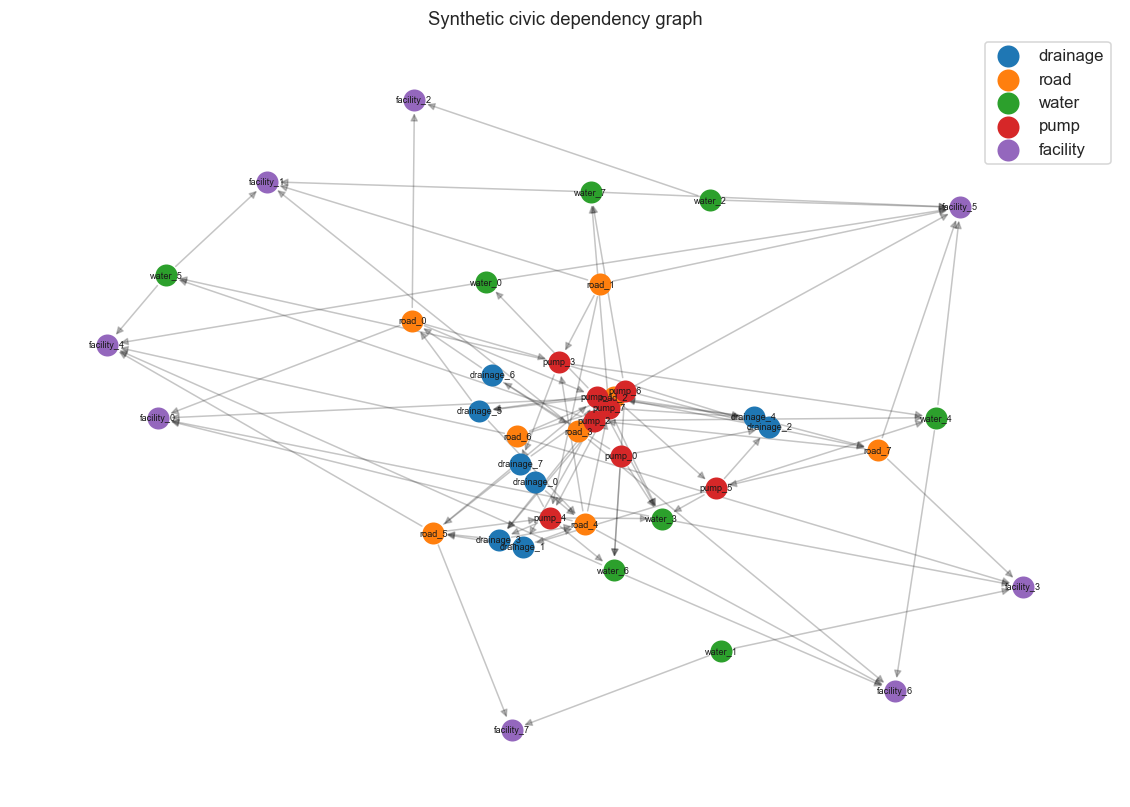

In [4]:
pos=nx.spring_layout(g,seed=SEED)
colors={kind:sns.color_palette('tab10')[i] for i,kind in enumerate(NODE_TYPES)}
plt.figure(figsize=(13,9))
nx.draw_networkx_edges(g,pos,alpha=.25,arrows=True,arrowsize=10)
for kind in NODE_TYPES:
    nodes=[n for n,d in g.nodes(data=True) if d['node_type']==kind]
    nx.draw_networkx_nodes(g,pos,nodelist=nodes,node_color=[colors[kind]],node_size=180,label=kind)
nx.draw_networkx_labels(g,pos,font_size=6);plt.legend();plt.title('Synthetic civic dependency graph');plt.axis('off');plt.show()

### Degree and centrality distributions

Degree and betweenness expose bottleneck hypotheses, not measured real-world failure likelihood.

,node,node_type,criticality,resilience,in_degree,out_degree,betweenness
13,road_5,road,0.784001,0.374685,3,4,0.096071
25,pump_1,pump,0.718002,0.231881,3,4,0.093497
12,road_4,road,0.903526,0.589629,4,4,0.088375
27,pump_3,pump,0.706692,0.251722,3,4,0.068062
10,road_2,road,0.998372,0.688242,3,4,0.061314
28,pump_4,pump,0.796733,0.188511,3,4,0.058217
15,road_7,road,0.737848,0.195321,2,4,0.056562
3,drainage_3,drainage,0.853184,0.650687,3,2,0.056205
5,drainage_5,drainage,0.987035,0.306607,2,2,0.054042
31,pump_7,pump,0.626416,0.190531,2,4,0.050170


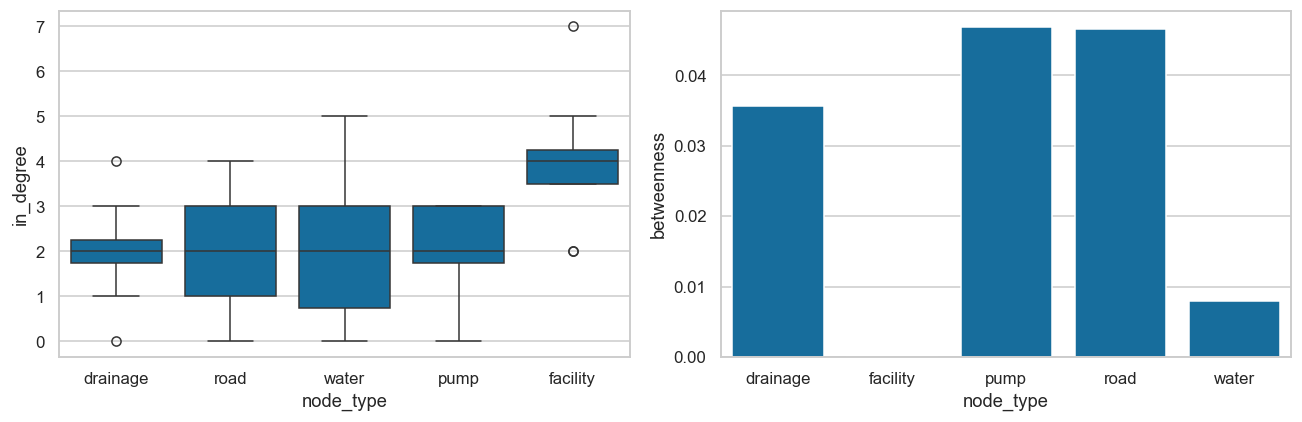

In [5]:
node_table['in_degree']=node_table.node.map(dict(g.in_degree()))
node_table['out_degree']=node_table.node.map(dict(g.out_degree()))
node_table['betweenness']=node_table.node.map(nx.betweenness_centrality(g))
display(node_table.sort_values('betweenness',ascending=False).head(10))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=node_table,x='node_type',y='in_degree',ax=ax[0])
sns.barplot(data=node_table.groupby('node_type',as_index=False).betweenness.mean(),x='node_type',y='betweenness',ax=ax[1]);plt.tight_layout();plt.show()

### Edge weights and dependency-type matrix

These distributions expose the simulation assumptions that drive later labels.

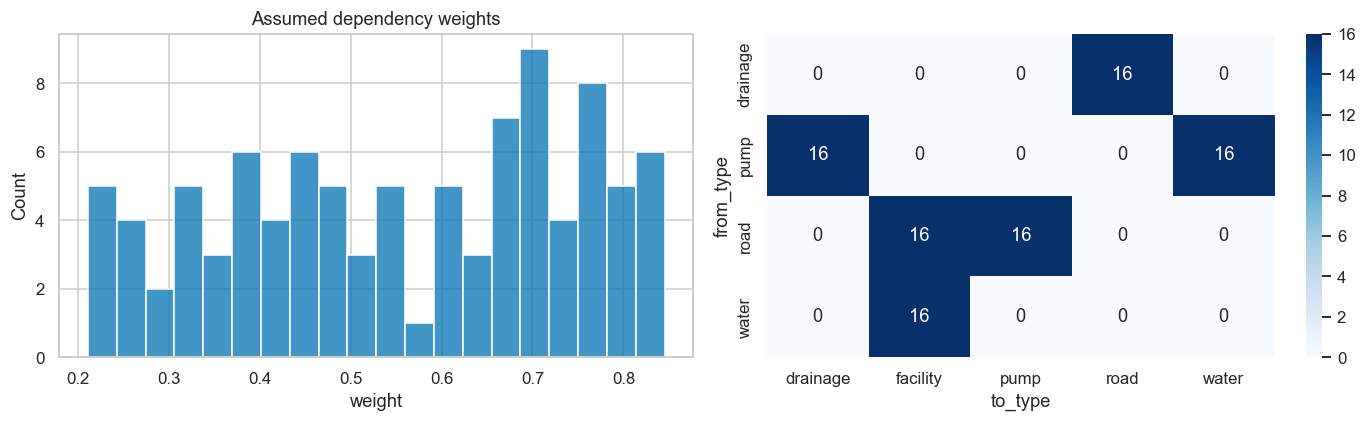

In [6]:
edge_table['from_type']=edge_table.source.map(dict(g.nodes(data='node_type')))
edge_table['to_type']=edge_table.target.map(dict(g.nodes(data='node_type')))
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(edge_table.weight,bins=20,ax=ax[0]);ax[0].set_title('Assumed dependency weights')
sns.heatmap(pd.crosstab(edge_table.from_type,edge_table.to_type),annot=True,fmt='d',ax=ax[1],cmap='Blues');plt.tight_layout();plt.show()

## 04. Reproducible cascade simulation

An independent-cascade process begins with two externally specified primary disruptions. Each newly disrupted node attempts transmission once to each outgoing neighbor with probability `clip(edge_weight × event_load × (1 − target_resilience),0,1)`. Successful transmission arrives after the edge delay. The earliest arrival wins; no spontaneous failures, repairs or interventions occur.

The probability law is a documented scenario assumption. Sixty-minute secondary outcomes are generated only after origin features are frozen. No future failure times or random outcomes enter the model features.

### One event and its time evolution

The deterministic NetworkX reachability baseline assumes every possible transmission succeeds; simulation adds uncertainty.

,node,failure_minute
0,pump_0,0
1,drainage_3,0
2,water_3,10


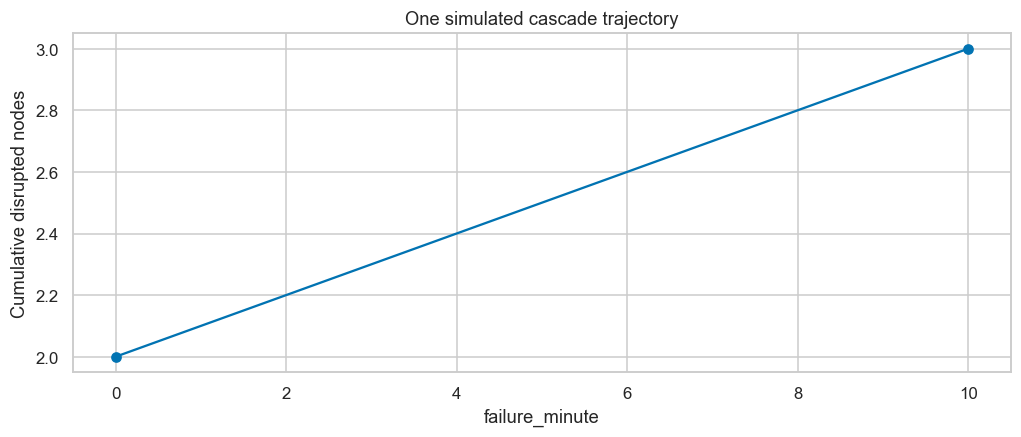

Rule reachable nodes 24 Actual simulated secondary 1


In [7]:
initial=['pump_0','drainage_3'];load=1.1
future=simulate_event(g,initial,load,seed=42)
trace=pd.DataFrame({'node':list(future),'failure_minute':list(future.values())}).sort_values('failure_minute')
display(trace)
trace.groupby('failure_minute').size().cumsum().plot(marker='o',title='One simulated cascade trajectory',ylabel='Cumulative disrupted nodes');plt.show()
print('Rule reachable nodes',len(propagation_rule(g,initial)),'Actual simulated secondary',len(future)-len(initial))

### Visualize primary and secondary disruptions

This map shows generated outcomes, not observations of municipal failures.

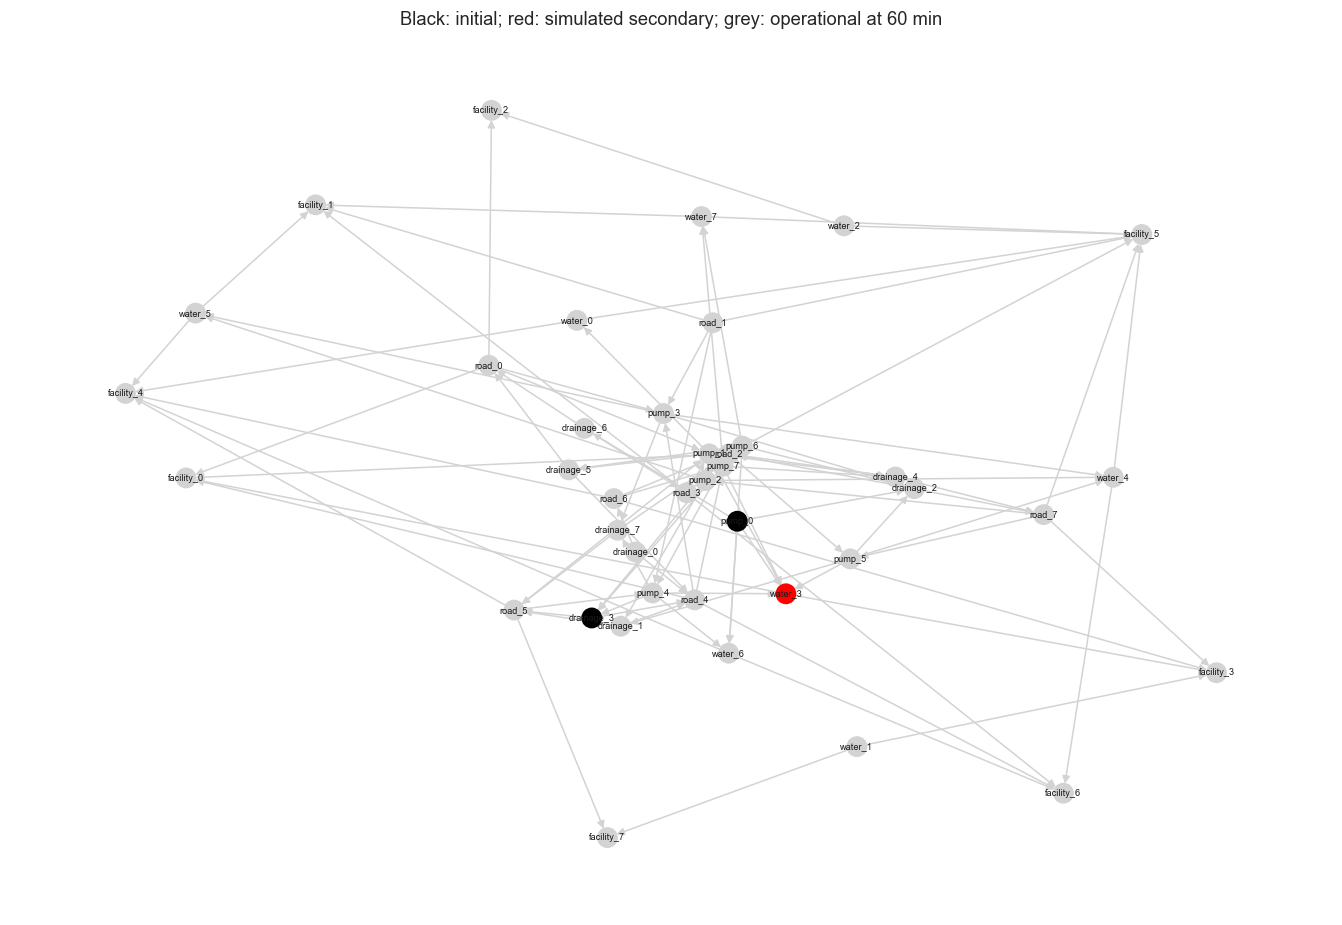

In [8]:
plt.figure(figsize=(12,8))
node_colors=['black' if node in initial else ('red' if node in future else 'lightgrey') for node in g]
nx.draw(g,pos,node_color=node_colors,node_size=160,with_labels=True,font_size=6,edge_color='lightgrey',arrows=True)
plt.title('Black: initial; red: simulated secondary; grey: operational at 60 min');plt.show()

## 05. Event dataset and coverage

Generate six graph realizations and 90 distinct primary-disruption pairs per graph. Graphs 100–103 provide training, validation and new-event tests; graphs 104–105 are wholly held out and use heavier load ranges. Repeated nodes within one event are dependent and must stay in one split.

### Generate and audit labeled scenarios

Synthetic provenance, event IDs and graph IDs remain attached for grouping and audit, but IDs are excluded from predictors.

In [9]:
data,graphs,manifest=generate_cascades(SEED)
display(data.head());display(data.groupby(['period','node_type']).target.agg(['count','mean']))
print('Rows',len(data),'events',data.event_id.nunique(),'graphs',len(graphs),'nulls outside failure-time audit',data.drop(columns='failure_minute').isna().sum().sum())
write_json(OUT/'scenario_manifest.json',manifest)
data.to_csv(OUT/'scenario_data.csv',index=False)

,node_id,node_type,criticality,resilience,load,in_degree,out_degree,betweenness,failed_predecessors,direct_exposure,seed_distance,upstream_failed_fraction,target,event_id,graph_id,period,failure_minute
0,drainage_0,drainage,0.884487,0.478105,0.968947,0,2,0.000000,0,0.0,99,0.000000,0,100-0,synthetic-civic-100,train,NaN
1,drainage_1,drainage,0.502204,0.173623,0.968947,2,2,0.041115,0,0.0,3,0.043478,0,100-0,synthetic-civic-100,train,NaN
2,drainage_2,drainage,0.981558,0.478059,0.968947,4,2,0.049243,0,0.0,3,0.043478,0,100-0,synthetic-civic-100,train,NaN
3,drainage_3,drainage,0.853184,0.650687,0.968947,3,2,0.056205,0,0.0,3,0.043478,0,100-0,synthetic-civic-100,train,NaN
4,drainage_5,drainage,0.987035,0.306607,0.968947,2,2,0.054042,0,0.0,6,0.043478,0,100-0,synthetic-civic-100,train,NaN


count      mean
period            node_type                 
test_seen_graph   drainage     454  0.061674
                  facility     458  0.117904
                  pump         456  0.050439
                  road         459  0.067538
                  water        453  0.057395
test_unseen_graph drainage    1373  0.086672
                  facility    1366  0.166911
                  pump        1355  0.073801
                  road        1385  0.111191
                  water       1361  0.079353
train             drainage    1820  0.067582
                  facility    1824  0.114035
                  pump        1823  0.068020
                  road        1812  0.064570
                  water       1841  0.082021
validation        drainage     458  0.061135
                  facility     454  0.114537
                  pump         461  0.075922
                  road         454  0.068282
                  water        453  0.070640

Rows 20520 events 540 graphs 6 nulls outside failure-time audit 0


### Class balance and node-type differences

Failure-time NaN means no disruption in the 60-minute simulation horizon, not a missing measured incident report.

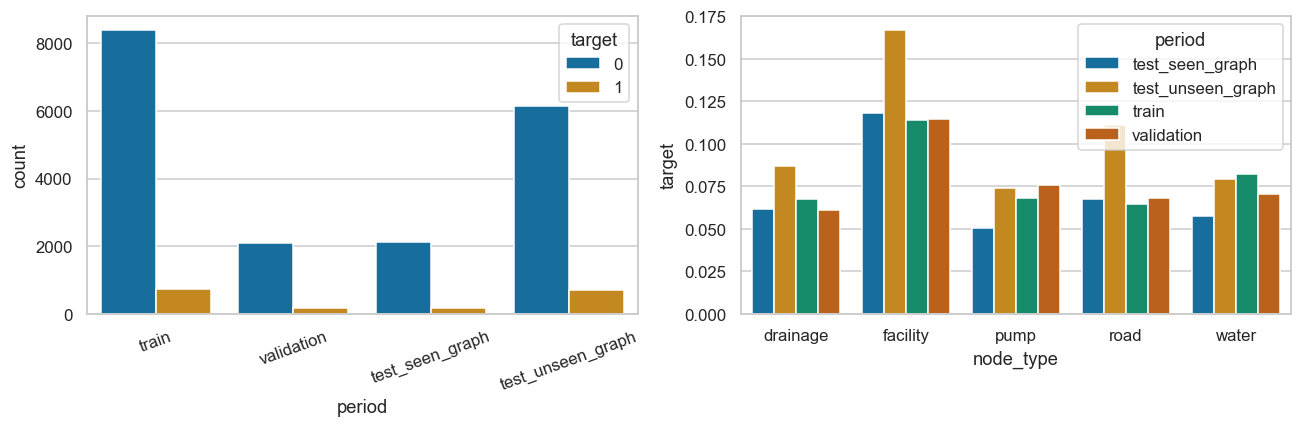

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=data,x='period',hue='target',ax=ax[0]);ax[0].tick_params(axis='x',rotation=20)
sns.barplot(data=data.groupby(['period','node_type'],as_index=False).target.mean(),x='node_type',y='target',hue='period',ax=ax[1]);plt.tight_layout();plt.show()

## 06. Snapshot features and leakage prevention

Features include node type, static criticality/resilience, degree/betweenness, event load, number/weight of already-disrupted predecessors, shortest hop distance from primary disruptions and fraction of ancestors already disrupted. All refer to the graph and status at origin. `failure_minute`, target, event ID, graph ID and future outcomes are forbidden inputs.

### Feature schema and availability

Operational nodes only receive predictions; initially disrupted nodes cannot trivially inflate target accuracy.

In [11]:
feature_names=FEATURES;numeric=NUMERIC;categorical=CATEGORICAL
assert not {'target','failure_minute','event_id','graph_id','node_id'}.intersection(feature_names)
first=manifest[0];origin=node_features(graphs[first['graph_id']],first['initial'],first['load'])
assert not set(origin.node_id).intersection(first['initial'])
pd.testing.assert_frame_equal(origin,node_features(graphs[first['graph_id']],first['initial'],first['load']))
write_json(OUT/'feature_schema.json',{'numeric':numeric,'categorical':categorical,'available_at':'origin graph/status only'})
display(origin.head())

,node_id,node_type,criticality,resilience,load,in_degree,out_degree,betweenness,failed_predecessors,direct_exposure,seed_distance,upstream_failed_fraction
0,drainage_0,drainage,0.884487,0.478105,0.968947,0,2,0.000000,0,0.0,99,0.000000
1,drainage_1,drainage,0.502204,0.173623,0.968947,2,2,0.041115,0,0.0,3,0.043478
2,drainage_2,drainage,0.981558,0.478059,0.968947,4,2,0.049243,0,0.0,3,0.043478
3,drainage_3,drainage,0.853184,0.650687,0.968947,3,2,0.056205,0,0.0,3,0.043478
4,drainage_5,drainage,0.987035,0.306607,0.968947,2,2,0.054042,0,0.0,6,0.043478


### Feature distributions and correlations

Correlation may be created by topology; importance does not imply causal engineering benefit.

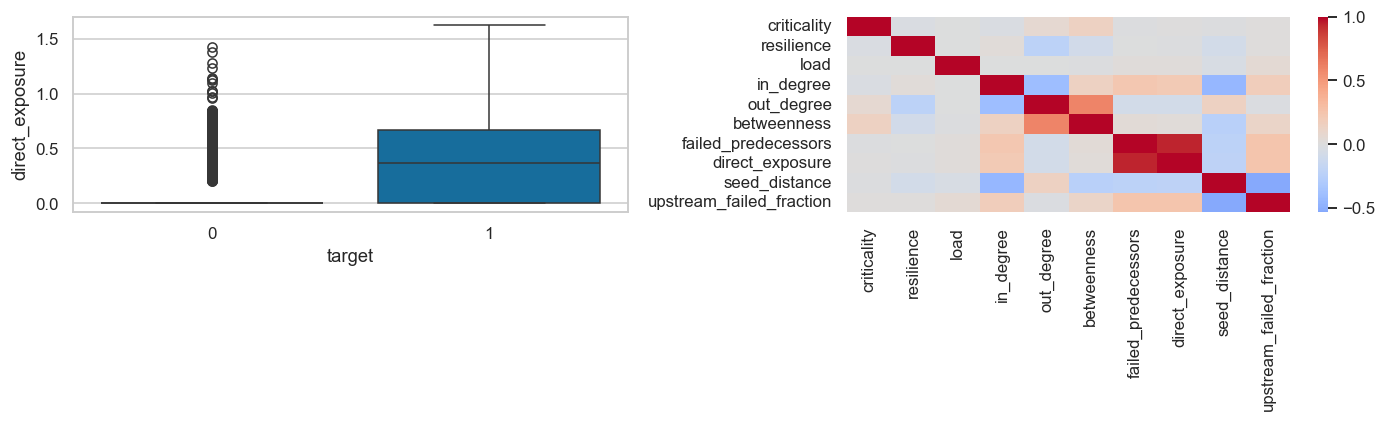

In [12]:
train=data[data.period.eq('train')].copy()
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=train,x='target',y='direct_exposure',ax=ax[0])
sns.heatmap(train[numeric].corr(),cmap='coolwarm',center=0,ax=ax[1]);plt.tight_layout();plt.show()

## 07. Event-grouped training strategy

Use three GroupKFold folds grouped by complete event ID within development. Final testing reports unseen events on familiar graphs separately from unseen graphs under heavier loads. The same primary pair never appears in train/validation/test within a graph. There is no random node-row split.

### Construct and verify event groups

Model selection sees only development events; threshold selection uses separate validation events.

In [13]:
val=data[data.period.eq('validation')].copy();test=data[data.period.str.startswith('test')].copy()
Xtrain,ytrain=train[feature_names],train.target
Xval,yval=val[feature_names],val.target
Xtest,ytest=test[feature_names],test.target
folds=list(GroupKFold(n_splits=3).split(Xtrain,ytrain,groups=train.event_id))
for tr,va in folds:assert not set(train.iloc[tr].event_id)&set(train.iloc[va].event_id)
assert not set(train.event_id)&set(test.event_id)
assert not set(train.graph_id)&set(test[test.period.eq('test_unseen_graph')].graph_id)
print('Train/validation/test rows',len(train),len(val),len(test))

Train/validation/test rows 9120 2280 9120


### NetworkX rule propagation baseline

Directed delay-limited reachability is conservative because it ignores failed transmission and resilience.

In [14]:
lookup={r['event_id']:r for r in manifest}
rule_scores=[]
for event,group in test.groupby('event_id',sort=False):
    r=lookup[event];reach=propagation_rule(graphs[r['graph_id']],r['initial'])
    rule_scores.extend((idx,float(node in reach)) for idx,node in zip(group.index,group.node_id))
rule_scores=pd.Series(dict(rule_scores)).reindex(test.index)
print('Rule final coverage',rule_scores.mean())

Rule final coverage 0.46337719298245617


## 08. Model comparison and hyperparameter analysis

Compare a prior baseline, Logistic Regression and XGBoost. NetworkX propagation remains an external deterministic baseline. Tuning and threshold selection use grouped development and validation data; no automatic dispatch action is coupled to the classifier.

### Declare model candidates

All learned transforms are refitted within CV. The prior baseline is eligible to win; class balance is not altered on evaluation data.

In [15]:
models={'Prior':pipeline(DummyClassifier(strategy='prior'),numeric,categorical),
        'Logistic':pipeline(LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),numeric,categorical,True),
        'XGBoost':pipeline(XGBClassifier(n_estimators=140,max_depth=3,learning_rate=.06,subsample=.85,colsample_bytree=.85,eval_metric='logloss',tree_method='hist',n_jobs=2,random_state=SEED),numeric,categorical)}
print('Candidates',list(models))

Candidates ['Prior', 'Logistic', 'XGBoost']


### Cross-validated comparisons

Average precision (PR-AUC summary) is primary; fold dispersion is reported. Development scores are selection estimates, not independent final performance.

,AP,AP_std,Brier
model,,,
XGBoost,0.461121,0.037942,0.054884
Logistic,0.456340,0.013166,0.142540
Prior,0.079276,0.009907,0.073073


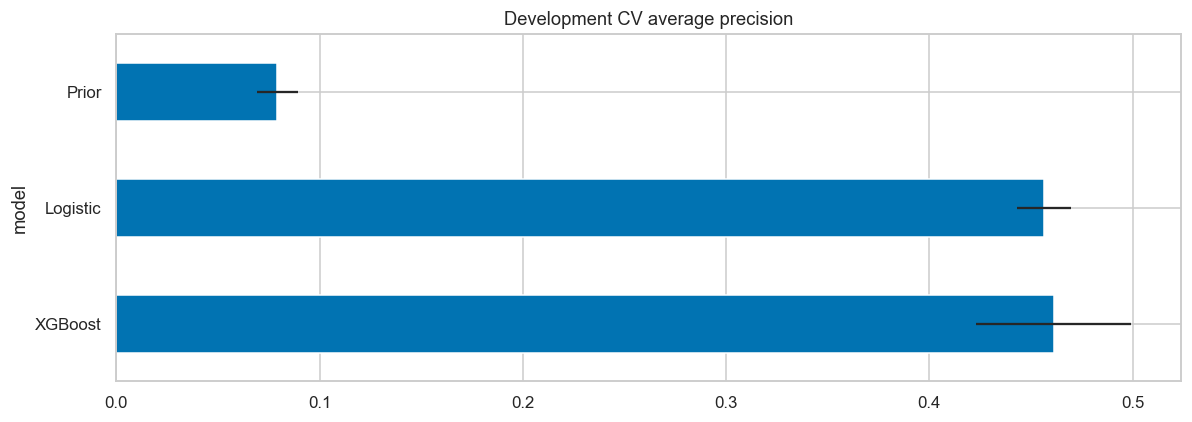

In [16]:
rows=[]
for name,model in models.items():
    scores=cross_validate(model,Xtrain,ytrain,cv=folds,scoring={'ap':'average_precision','brier':'neg_brier_score'},error_score='raise',n_jobs=1)
    for i in range(len(folds)):rows.append({'model':name,'fold':i,'AP':scores['test_ap'][i],'Brier':-scores['test_brier'][i]})
cv_results=pd.DataFrame(rows)
summary=cv_results.groupby('model').agg(AP=('AP','mean'),AP_std=('AP','std'),Brier=('Brier','mean')).sort_values('AP',ascending=False)
display(summary);cv_results.to_csv(OUT/'candidate_cv.csv',index=False)
summary.AP.plot.barh(xerr=summary.AP_std,title='Development CV average precision');plt.tight_layout();plt.show()

### Declared hyperparameter searches

Tune Logistic and XGBoost with four sampled settings each. The modest budget is explicit and repeatable; test labels never enter selection.

In [17]:
spaces={'Logistic':{'model__C':[.01,.1,1,10,100],'model__class_weight':[None,'balanced']},
        'XGBoost':{'model__n_estimators':[80,140,220],'model__max_depth':[2,3,5],'model__learning_rate':[.03,.08,.15],'model__min_child_weight':[1,5,10]}}
searches={};ranking=summary.AP.to_dict()
for name,space in spaces.items():
    search=RandomizedSearchCV(models[name],space,n_iter=4,scoring='average_precision',cv=folds,refit=True,n_jobs=1,random_state=SEED,error_score='raise')
    search.fit(Xtrain,ytrain);searches[name]=search;ranking[name+' tuned']=search.best_score_
    trials=pd.DataFrame(search.cv_results_);trials.to_csv(OUT/(name+'_tuning.csv'),index=False)
    display(trials.sort_values('rank_test_score')[['rank_test_score','mean_test_score','std_test_score','params']])
selected=max(ranking,key=ranking.get)
model=searches[selected.removesuffix(' tuned')].best_estimator_ if selected.endswith(' tuned') else clone(models[selected]).fit(Xtrain,ytrain)
print('Locked CV choice:',selected)

,rank_test_score,mean_test_score,std_test_score,params
0,1,0.475132,0.026623,"{'model__class_weight': None, 'model__C': 100}"
2,2,0.456340,0.010750,"{'model__class_weight': 'balanced', 'model__C'..."
3,3,0.424201,0.021652,"{'model__class_weight': None, 'model__C': 0.01}"
1,4,0.419597,0.009401,"{'model__class_weight': 'balanced', 'model__C'..."


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.468413,0.032774,"{'model__n_estimators': 80, 'model__min_child_..."
3,2,0.464263,0.032865,"{'model__n_estimators': 140, 'model__min_child..."
1,3,0.463906,0.036709,"{'model__n_estimators': 80, 'model__min_child_..."
2,4,0.456732,0.029799,"{'model__n_estimators': 140, 'model__min_child..."


Locked CV choice: Logistic tuned


### Choose a validation-only threshold

Choose the highest threshold among tied validation F1 scores. This is a predictive tradeoff, not an authorized intervention policy. Calibration is assessed on final data without retuning.

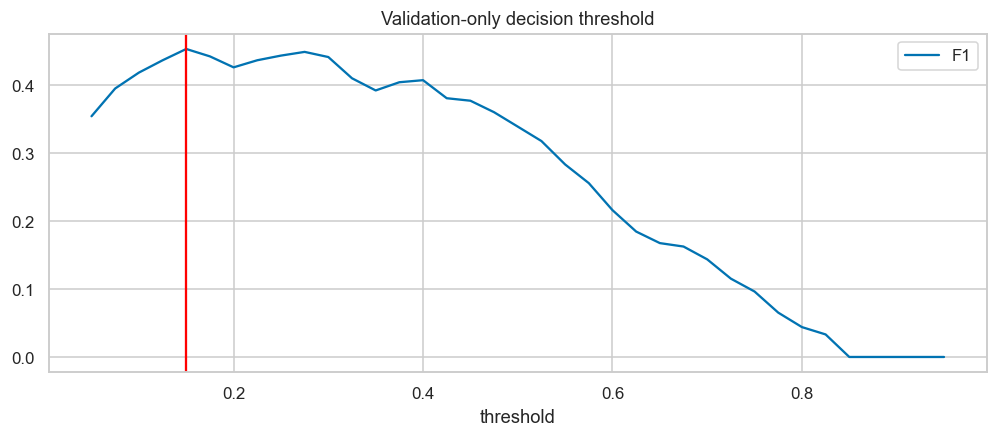

Locked threshold 0.15


In [18]:
pval=model.predict_proba(Xval)[:,1]
threshold,threshold_table=choose_threshold(yval,pval)
threshold_table.to_csv(OUT/'threshold_validation.csv',index=False)
threshold_table.plot(x='threshold',y='F1',title='Validation-only decision threshold');plt.axvline(threshold,color='red');plt.show()
print('Locked threshold',threshold)

## 09. Final generalization and calibration

Report unseen disruption events and unseen graph/load conditions separately. The pooled metric can obscure a failure on new topology. All metrics concern simulation-generated labels.

### Locked final evaluation

No final-period outcome is used to pick the model or change its threshold.

precision                      0.316444
recall                         0.788749
F1                             0.451677
PR_AUC_average_precision       0.461236
ROC_AUC                        0.893923
Brier                          0.066500
false_positive_rate            0.179901
false_positives             1484.000000
false_negatives              184.000000
n                           9120.000000
prevalence                     0.095504
dtype: float64

              precision    recall  f1-score   support

           0       0.97      0.82      0.89      8249
           1       0.32      0.79      0.45       871

    accuracy                           0.82      9120
   macro avg       0.64      0.80      0.67      9120
weighted avg       0.91      0.82      0.85      9120



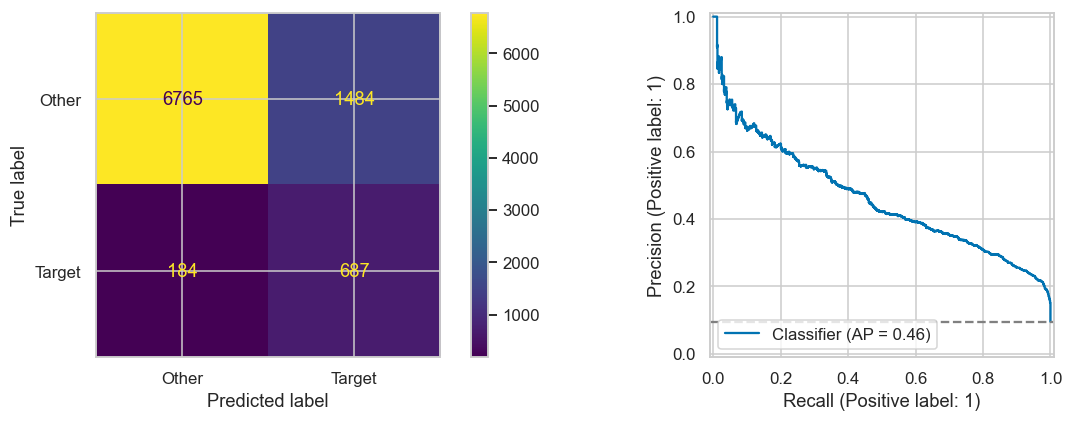

In [19]:
ptest=model.predict_proba(Xtest)[:,1]
metrics=binary_metrics(ytest,ptest,threshold)
display(pd.Series(metrics));print(classification_report(ytest,ptest>=threshold,zero_division=0))
write_json(OUT/'metrics.json',metrics)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ConfusionMatrixDisplay.from_predictions(ytest,ptest>=threshold,ax=ax[0],display_labels=['Other','Target'])
PrecisionRecallDisplay.from_predictions(ytest,ptest,ax=ax[1]);ax[1].axhline(np.mean(ytest),ls='--',color='grey')
plt.tight_layout();plt.show()

### Probability reliability and error distribution

Uncalibrated scores may be poorly calibrated under domain shift; a probability-looking number is not proof of real-world validity.

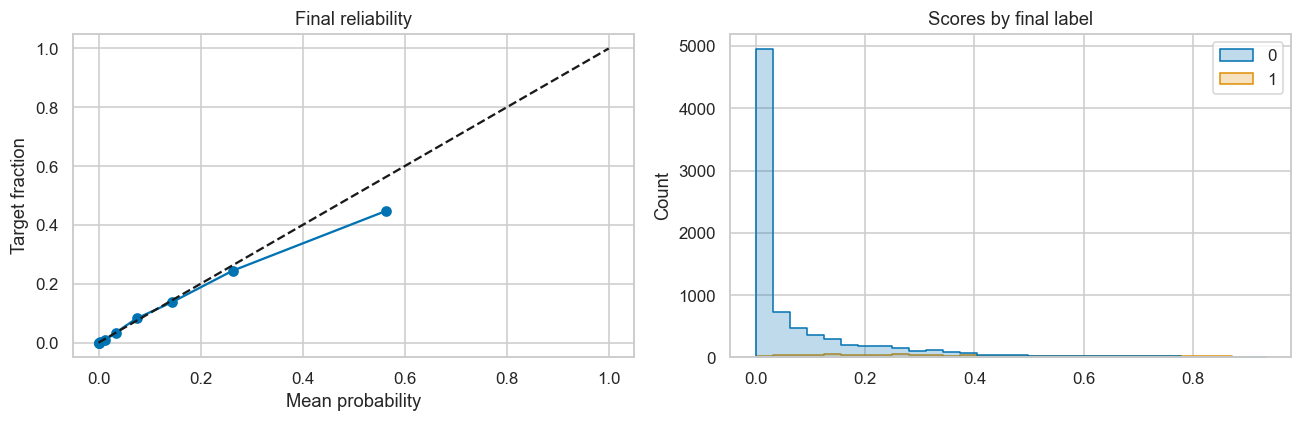

In [20]:
fraction,mean=calibration_curve(ytest,ptest,n_bins=10,strategy='quantile')
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(mean,fraction,marker='o');ax[0].plot([0,1],[0,1],'k--');ax[0].set(title='Final reliability',xlabel='Mean probability',ylabel='Target fraction')
sns.histplot(x=ptest,hue=np.asarray(ytest),bins=30,element='step',ax=ax[1]);ax[1].set_title('Scores by final label')
plt.tight_layout();plt.show()

### Baseline and domain-shift comparisons

Final results never change the already locked model choice.

In [21]:
comparison=pd.DataFrame([{'method':selected,**metrics},{'method':'NetworkX reachability',**binary_metrics(ytest,rule_scores,.5)}])
display(comparison);comparison.to_csv(OUT/'final_comparison.csv',index=False)
results=test[['node_id','node_type','event_id','graph_id','period','target','failure_minute']].copy();results['probability']=ptest;results['predicted']=ptest>=threshold
results.to_csv(OUT/'test_predictions.csv',index=False)
slices=pd.DataFrame([{'split':name,**binary_metrics(z.target,z.probability,threshold)} for name,z in results.groupby('period')])
display(slices);slices.to_csv(OUT/'generalization_slices.csv',index=False)

,method,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Logistic tuned,0.316444,0.788749,0.451677,0.461236,0.893923,0.066500,0.179901,1484,184,9120,0.095504
1,NetworkX reachability,0.206105,1.000000,0.341770,0.206105,0.796642,0.367873,0.406716,3355,0,9120,0.095504


,split,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,test_seen_graph,0.300000,0.740741,0.427046,0.409314,0.913435,0.050999,0.132200,280,42,2280,0.071053
1,test_unseen_graph,0.320158,0.799718,0.457258,0.473428,0.887419,0.071667,0.196379,1204,142,6840,0.103655


### Per-node-type errors

Critical facilities can have different exposure and error rates than pumps or roads.

,node_type,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,drainage,0.321637,0.748299,0.449898,0.464194,0.907957,0.055316,0.138095,232,37,1827,0.080460
1,facility,0.326446,0.840426,0.470238,0.472314,0.836797,0.105953,0.317121,489,45,1824,0.154605
2,pump,0.298305,0.715447,0.421053,0.390649,0.904419,0.052367,0.122630,207,35,1811,0.067918
3,road,0.365482,0.778378,0.497409,0.516505,0.913399,0.063662,0.150693,250,41,1844,0.100325
4,water,0.260870,0.805970,0.394161,0.469574,0.903474,0.055087,0.182143,306,26,1814,0.073870


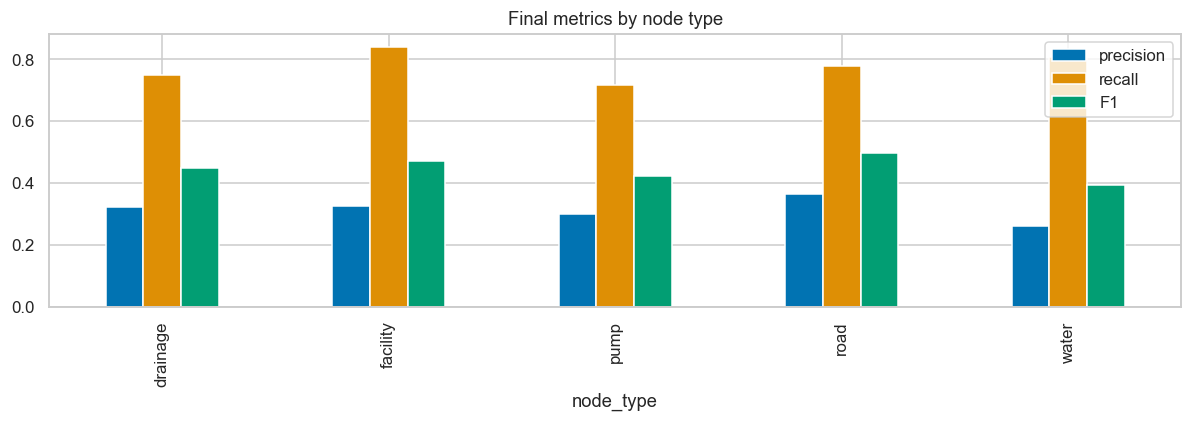

In [22]:
types=pd.DataFrame([{'node_type':kind,**binary_metrics(z.target,z.probability,threshold)} for kind,z in results.groupby('node_type')])
display(types);types.plot.bar(x='node_type',y=['precision','recall','F1'],title='Final metrics by node type');plt.tight_layout();plt.show()
types.to_csv(OUT/'node_type_metrics.csv',index=False)

## 10. Error cases and sensitivity

Inspect false positives/negatives and controlled load shifts. Learned risks need not obey every monotonic physical expectation; this simulator is not a calibrated infrastructure model.

### Inspect incorrect node predictions

An apparent false positive can be a plausible stochastic pathway that simply did not occur in that simulation draw.

In [23]:
wrong=results[results.predicted!=results.target]
display(wrong.sort_values('probability',ascending=False).head(12))
print('Incorrect node predictions',len(wrong),'from',results.event_id.nunique(),'independent final events')

,node_id,node_type,event_id,graph_id,period,target,failure_minute,probability,predicted
19983,facility_3,facility,105-75,synthetic-civic-105,test_unseen_graph,0,NaN,0.875105,True
15829,water_6,water,104-56,synthetic-civic-104,test_unseen_graph,0,NaN,0.873443,True
18364,road_3,road,105-33,synthetic-civic-105,test_unseen_graph,0,NaN,0.860081,True
14372,road_1,road,104-18,synthetic-civic-104,test_unseen_graph,0,NaN,0.847681,True
18913,pump_5,pump,105-47,synthetic-civic-105,test_unseen_graph,0,NaN,0.846923,True
10165,water_4,water,102-87,synthetic-civic-102,test_seen_graph,0,NaN,0.844235,True
18221,water_3,water,105-29,synthetic-civic-105,test_unseen_graph,0,NaN,0.841445,True
18458,pump_5,pump,105-35,synthetic-civic-105,test_unseen_graph,0,NaN,0.839839,True
18335,water_3,water,105-32,synthetic-civic-105,test_unseen_graph,0,NaN,0.835057,True
13725,road_1,road,104-1,synthetic-civic-104,test_unseen_graph,0,NaN,0.832977,True


Incorrect node predictions 1668 from 240 independent final events


### Risk sensitivity to load

Use the same graph/initial disruptions while changing only a declared scenario input. No labels are changed to flatter a model.

,load,mean_risk
0,0.50,0.056946
1,0.75,0.090712
2,1.00,0.138332
3,1.25,0.202161
4,1.50,0.282772


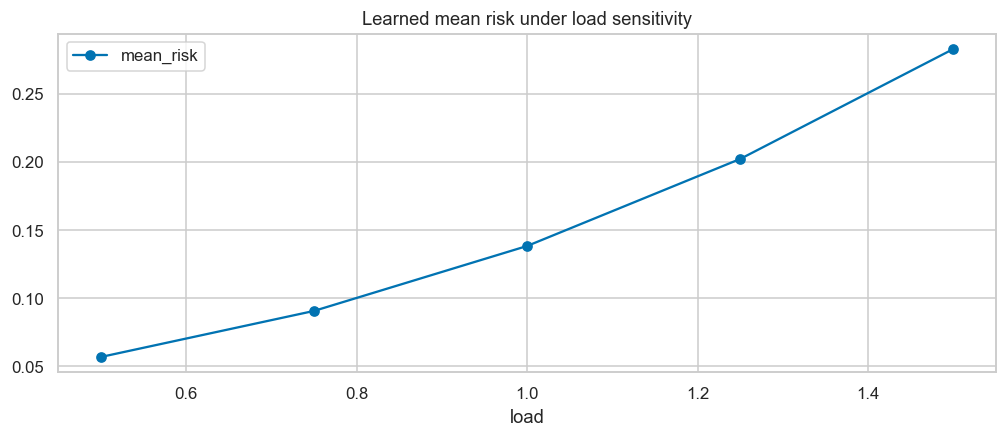

In [24]:
sensitivity=[]
for load_value in [.5,.75,1.,1.25,1.5]:
    frame=node_features(g,initial,load_value)
    sensitivity.append({'load':load_value,'mean_risk':model.predict_proba(frame[feature_names])[:,1].mean()})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity)
sensitivity.plot(x='load',y='mean_risk',marker='o',title='Learned mean risk under load sensitivity');plt.show()

## 11. Explainability

Associations reflect the simulator and graph-feature construction. No SHAP feature contribution is an intervention effect.

### Permutation importance of the chosen model

Feature associations are not causal effects. Correlated variables can divide importance; no feature reselection occurs after final evaluation.

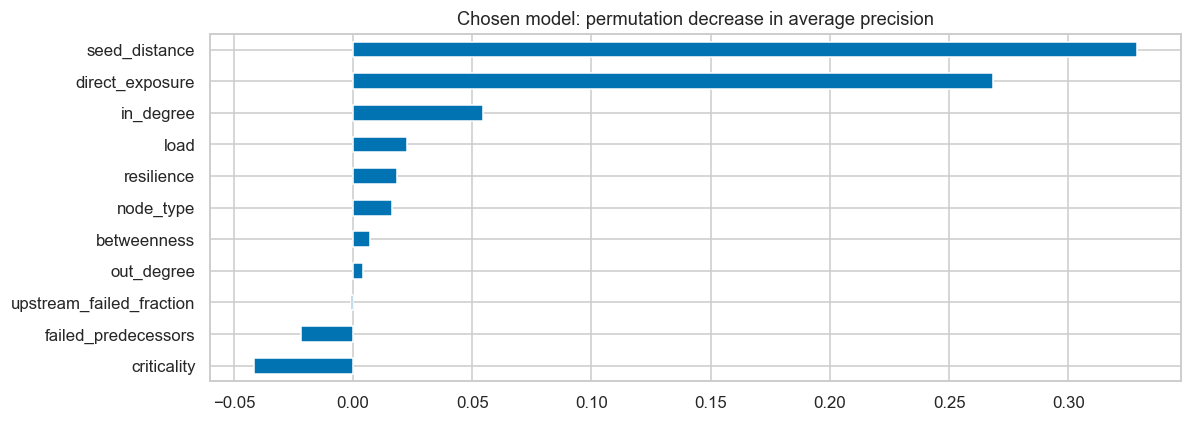

In [25]:
sample=Xval.sample(min(160,len(Xval)),random_state=SEED)
y_sample=yval.loc[sample.index]
pi=permutation_importance(model,sample,y_sample,scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
importance=pd.Series(pi.importances_mean,index=feature_names).sort_values()
importance.tail(15).plot.barh(title='Chosen model: permutation decrease in average precision');plt.tight_layout();plt.show()
importance.to_csv(OUT/'permutation_importance.csv')

### SHAP global and individual explanation

SHAP explains the fitted raw classifier output. If a prior baseline wins, an auxiliary XGBoost explanation is explicitly identified.

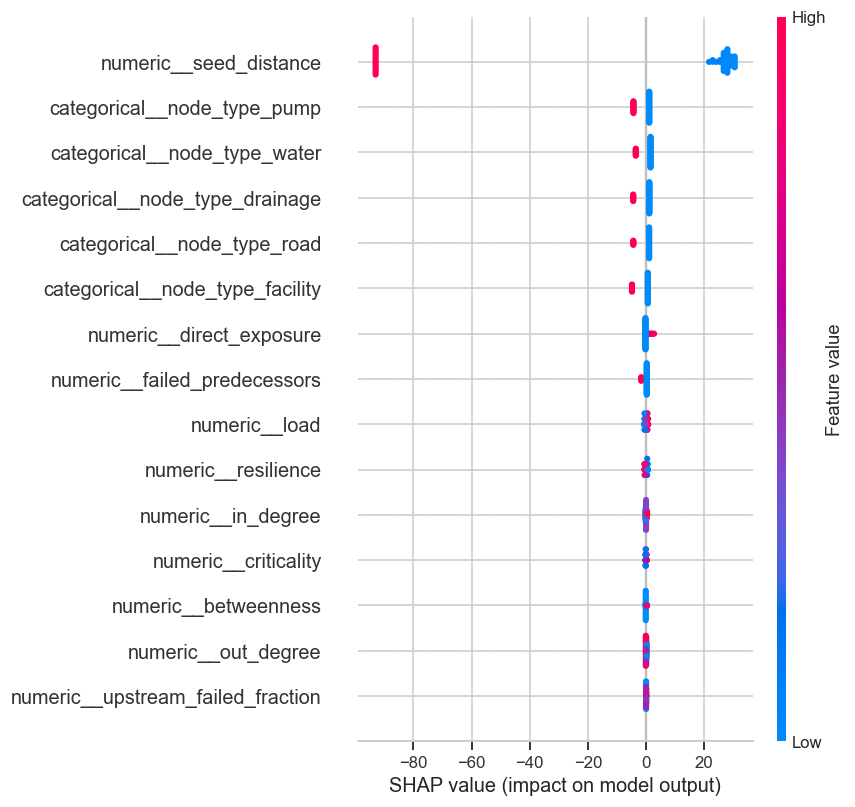

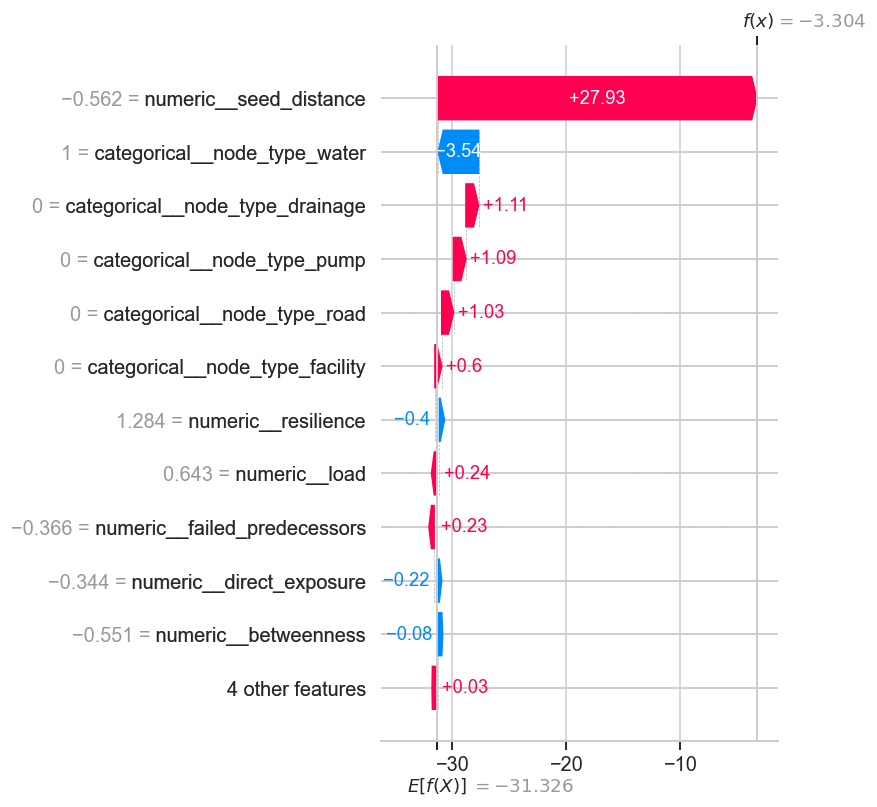

In [26]:
import shap
explained=model
if isinstance(model.named_steps['model'],DummyClassifier):
    explained=searches['XGBoost'].best_estimator_;print('Auxiliary XGBoost, not selected prior baseline')
transformed=explained.named_steps['preprocess'].transform(sample.iloc[:60])
classifier=explained.named_steps['model']
if isinstance(classifier,LogisticRegression):
    background=explained.named_steps['preprocess'].transform(Xtrain.sample(min(100,len(Xtrain)),random_state=SEED))
    ex=shap.LinearExplainer(classifier,background)(transformed)
else:
    ex=shap.TreeExplainer(classifier)(transformed)
    if ex.values.ndim==3:ex=ex[:,:,1]
ex.feature_names=list(explained.named_steps['preprocess'].get_feature_names_out())
shap.plots.beeswarm(ex,max_display=15,show=False);plt.tight_layout();plt.show()
shap.plots.waterfall(ex[0],max_display=12,show=False);plt.tight_layout();plt.show()

## 12. Versioned export and inference validation

Reuse the shared graph serialization and `src/civicflux/` component namespace. Unsupported node types, invalid edges, unknown initial nodes, out-of-range load and naive snapshot timestamps are rejected. Inference returns only operational nodes and has no graph mutation or dispatch side effect.

### Export fitted model and graph configurations

The graph artifact records every sampled dependency assumption, making the scenario reproducible.

In [27]:
metadata={'component':'cascade_risk','version':'1.0.0','selected_model':selected,'threshold':threshold,'horizon_minutes':60,'synthetic':True,'research_only':True,
          'metrics':metrics,'training_graphs':sorted(train.graph_id.unique()),'dispatch_allowed':False,'label':'secondary disruption by +60 min',
          'limitations':['Synthetic dependency weights','No verified municipal graph','No real cascade labels','Stochastic labels and event dependence']}
write_json(OUT/'metadata.json',metadata)
write_json(OUT/'graph_configurations.json',{key:graph_config(value) for key,value in graphs.items()})
bundle=CascadeBundle(model,threshold,metadata);joblib.dump(bundle,OUT/'pipeline.joblib')
loaded=joblib.load(OUT/'pipeline.joblib')
output=loaded.predict(g,initial,1.1,'2026-10-25T00:00:00Z')
assert output==bundle.predict(g,initial,1.1,'2026-10-25T00:00:00Z')
assert graph_fingerprint(from_config(graph_config(g)))==graph_fingerprint(g)
write_json(OUT/'example_prediction.json',output)
display(pd.DataFrame(output['nodes']).head())

,node_id,risk,review
0,drainage_0,8.503965e-55,False
1,drainage_1,1.744511e-02,False
2,drainage_2,5.305352e-01,True
3,drainage_4,5.790985e-02,False
4,drainage_5,6.196277e-02,False


## 13. CivicFlux integration and conclusions

The component exports node-level risk with a 60-minute horizon, graph fingerprint, provenance, version and warnings. The current workspace has no live CivicFlux graph API/approval schema; integration is a reusable pure contract, not fabricated backend wiring. It shares graph representation with the water topology reader and will supply hypothetical node/criticality context to Notebook 08.

Before field use, obtain a verified dependency graph, measured weights/delays, incident timelines and restoration data; validate across future incidents and cities; calibrate probabilities; retain independent corroboration and approval gates. Predictions must not automatically allocate or dispatch resources.

### Actual results summary

These values are produced by the executed experiment, not assumed accuracy.

In [28]:
print('Selected',selected,'events',data.event_id.nunique(),'rows',len(data))
print(json.dumps(metrics,indent=2));display(slices)

Selected Logistic tuned events 540 rows 20520
{
  "precision": 0.31644403500690926,
  "recall": 0.7887485648679678,
  "F1": 0.4516765285996055,
  "PR_AUC_average_precision": 0.4612357247934787,
  "ROC_AUC": 0.8939231962013555,
  "Brier": 0.06649985432463724,
  "false_positive_rate": 0.17990059401139533,
  "false_positives": 1484,
  "false_negatives": 184,
  "n": 9120,
  "prevalence": 0.09550438596491229
}


,split,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,test_seen_graph,0.300000,0.740741,0.427046,0.409314,0.913435,0.050999,0.132200,280,42,2280,0.071053
1,test_unseen_graph,0.320158,0.799718,0.457258,0.473428,0.887419,0.071667,0.196379,1204,142,6840,0.103655
